# 03 · 衍生品定价与对冲：QuantumBridge × 夸父云

        面向会基础 Python、概率和量子门的读者。本笔记可从首格运行到末格，默认不访问网络、
        不读取密钥、不产生真机任务。目标是一个可核验的小规模端到端案例，不等于该金融行业全部能力。

        数据全部为明确给定的合成数据，不是投资建议，不用于真实交易或生产风险管理。
        步骤：原理 → 输入与经典参考 → 电路与中间结果 → 本地实际采样 → 云任务与结果 → 最终比较。

In [1]:
from pathlib import Path
import json, os, sys
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, HTML
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'quantumbridge').is_dir()), None)
if ROOT is None:
    raise RuntimeError('Run this notebook from inside the QuantumBridge repository')
sys.path.insert(0, str(ROOT))
from quantumbridge.finance import build_finance_cases, run_local, FinanceCloudSession
from quantumbridge.finance.execution import circuit_artifact
from quantumbridge.finance.kernels import labels
from quantumbridge.devices import StatevectorDevice
import html
def pretty(value):
    print(json.dumps(value, ensure_ascii=False, indent=2))
def display_table(rows, fields):
    table = '<table><thead><tr>' + ''.join('<th>' + html.escape(f) + '</th>' for f in fields) + '</tr></thead><tbody>'
    for row in rows:
        table += '<tr>' + ''.join('<td>' + html.escape(str(row[f])) + '</td>' for f in fields) + '</tr>'
    display(HTML(table + '</tbody></table>'))
case = build_finance_cases()['derivatives']
if os.environ.get('QB_FINANCE_REPLAY_HARDWARE') == '1':
    from quantumbridge.finance.acceptance import restore_submitted_circuits
    case = restore_submitted_circuits(case, ROOT / 'output' / 'finance-hardware' / 'session.json')
    print('Using EXACT originally submitted QASM; strict plan/receipt hashes retained.')
print('Case:', case.key, '| quantum circuits:', len(case.experiments))
print('Result labels use q0-first ordering. Cloud ordering is calibrated separately.')

Using EXACT originally submitted QASM; strict plan/receipt hashes retained.
Case: derivatives | quantum circuits: 1
Result labels use q0-first ordering. Cloud ordering is calibrated separately.


## 1. 原理：风险中性定价、Delta 与静态对冲

一年期欧式期权采用三步二叉树。$u=e^{\sigma\sqrt{T/n}},d=1/u$，
$p_Q=(e^{rT/n}-d)/(u-d)$；它是风险中性概率，不能直接用于实际收益预测。
三比特记录上/下路径，$S_T=S_0u^kd^{n-k}$。独立步概率只需三个 RY 门。

看涨期权 $C=e^{-rT}E_Q[(S_T-K)^+]$，看跌同理。
共享同一组测量路径，计算现货上下各扰动1单位后的收益差：
$\Delta\approx e^{-rT}E_Q[(g(S_0+h)-g(S_0-h))/(2h)]$。
用样本方差估计价格标准误差，95%区间采用大样本正态近似，不包含硬件系统误差。

对一份空头看涨期权，初始持有 $\Delta$ 股，现金为 $C-\Delta S_0$；
到期损益 $\Pi=-g(S_T)+\Delta S_T+(C-\Delta S_0)e^{rT}$。
与不对冲的 $Ce^{rT}-g(S_T)$ 比较情景损益和标准差。
这是**静态 Delta 对冲**，不是逐日再平衡或无风险复制。离散树的精确价格与
Black–Scholes 解析价格不同是模型离散误差，不是量子测量错误。

实现步骤：设定期权参数 → 验证风险中性鞅关系 → 制备路径分布 → 测量 →
计算价格/Delta/标准误差 → 建立现金与股票对冲头寸 → 展示每个路径的最终损益。

## 2. 输入模型与精确对照
先检查输入、量纲和约束，随后所有量子采样结果使用同一个模型比较。

In [2]:
pretty(case.inputs)

{
  "spot": 100.0,
  "strike": 100.0,
  "rate": 0.03,
  "volatility": 0.2,
  "maturity": 1.0,
  "steps": 3,
  "spot_bump": 1.0,
  "risk_neutral_up_probability": 0.5145864613275055,
  "up": 1.1224009024456676,
  "down": 0.8909472522884107,
  "probabilities": [
    0.1143761977991435,
    0.1212501057274098,
    0.1212501057274098,
    0.12853712941853138,
    0.1212501057274098,
    0.12853712941853138,
    0.12853712941853138,
    0.13626209676303294
  ],
  "measure": "risk-neutral Q, not physical P"
}


In [3]:
paths = []
for i, label in enumerate(labels(3)):
    paths.append({'path': label, 'Q_probability': case.inputs['probabilities'][i],
                  'terminal_S': case.intermediate['terminal_prices'][i],
                  'call_payoff': case.intermediate['call_payoff'][i],
                  'delta_payoff': case.intermediate['delta_payoff'][i]})
display_table(paths, ['path', 'Q_probability', 'terminal_S', 'call_payoff', 'delta_payoff'])
discounted_terminal_mean = np.exp(-case.inputs['rate']) * np.dot(
    case.inputs['probabilities'], case.intermediate['terminal_prices'])
assert abs(discounted_terminal_mean - case.inputs['spot']) < 1e-10
print('Risk-neutral martingale checked; exact references:'); pretty(case.reference)

path,Q_probability,terminal_S,call_payoff,delta_payoff
000,0.1143761977991435,70.72223522189248,0.0,0.0
001,0.1212501057274098,89.09472522884107,0.0,0.0
010,0.1212501057274098,89.09472522884107,0.0,0.0
011,0.12853712941853138,112.24009024456676,12.240090244566758,1.122400902445662
100,0.1212501057274098,89.09472522884107,0.0,0.0
101,0.12853712941853138,112.24009024456676,12.240090244566758,1.122400902445662
110,0.12853712941853138,112.24009024456676,12.240090244566758,1.122400902445662
111,0.13626209676303294,141.39824580805166,41.398245808051655,1.4139824580805112


Risk-neutral martingale checked; exact references:
{
  "call_price": 10.054718210561122,
  "delta": 0.6069969747193295,
  "black_scholes_call": 9.413403383853016,
  "discretization_note": "binomial-vs-Black-Scholes difference is model error, not shot error"
}


## 3. 中间效果：电路、门数、理想概率

        所有实际提交门限定为 H、RY、RX、RZ、CX。概率/带符号实振幅加载在本地生成门序列，
        不是在云上执行 Python/NumPy。下格展示将提交的完整 QASM、量子比特数、双比特门数以及
        本地理想概率。真实设备的编译映射和噪声可能改变深度与分布。

In [4]:
for name, circuit in case.experiments.items():
    artifact = circuit_artifact(circuit)
    print(name, '| qubits:', artifact['num_qubits'], '| gates:', artifact['gates'],
          '| two-qubit gates:', artifact['two_qubit_gates'], '| SHA256:', artifact['sha256'])
    print(artifact['openqasm'])
    print('Ideal probabilities:', StatevectorDevice().probabilities(circuit))

risk_neutral_paths | qubits: 3 | gates: 3 | two-qubit gates: 0 | SHA256: f004e0cd4408e241cc70bd0ee738b4a0c2cf3f438b618b4ae5e8a3c02b4747a6
OPENQASM 2.0;
include "qelib1.inc";
qreg q[3];
creg c[3];
ry(1.5999733890172156) q[0];
ry(1.5999733890172159) q[1];
ry(1.5999733890172156) q[2];
measure q[0] -> c[0];
measure q[1] -> c[1];
measure q[2] -> c[2];

Ideal probabilities: {'000': 0.11437619779914351, '001': 0.12125010572740977, '010': 0.12125010572740985, '011': 0.12853712941853143, '100': 0.12125010572740977, '101': 0.12853712941853132, '110': 0.12853712941853143, '111': 0.1362620967630329}


## 4. 中间效果：1024 shots 本地实际采样
固定种子保证可重现。以下输出明确是本地模拟器，不是真机结果。

risk_neutral_paths local_simulator | measured shots: 1024
Raw measured counts: {'010': 127, '100': 120, '111': 160, '001': 118, '110': 130, '011': 126, '000': 126, '101': 117}


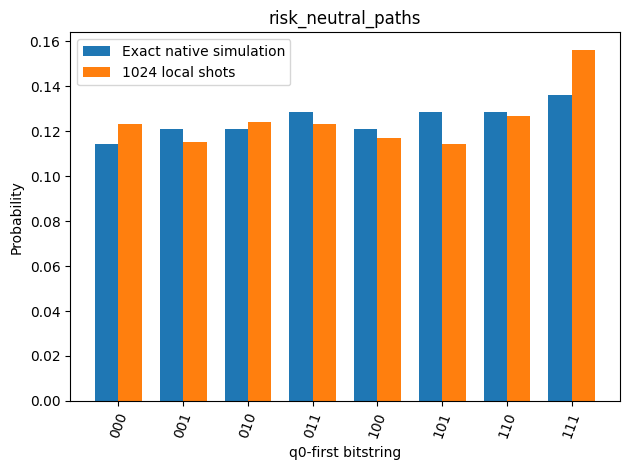

{
  "call_price": 10.604082028610357,
  "put_price": 7.268318290473128,
  "delta": 0.6111653021038301,
  "call_price_standard_error": 0.4322500740840186,
  "call_approximate_95pct_interval": [
    9.75687188340568,
    11.451292173815034
  ],
  "delta_standard_error": 0.018571803329481735,
  "unhedged_terminal_pnl": [
    10.92702440479655,
    10.92702440479655,
    10.92702440479655,
    -1.3130658397702089,
    10.92702440479655,
    -1.3130658397702089,
    -1.3130658397702089,
    -30.471221403255107
  ],
  "hedged_terminal_pnl": [
    -8.827804995153656,
    2.4008234103426815,
    2.4008234103426815,
    4.306377167915336,
    2.4008234103426815,
    4.306377167915336,
    4.306377167915336,
    -7.031325441821842
  ],
  "unhedged_pnl_std": 14.246288262071923,
  "hedged_pnl_std": 5.105514027236635,
  "put_call_parity_residual": 0.38031709298805083,
  "model": "3-step risk-neutral binomial; static delta hedge; not a continuous dynamic hedge"
}


In [5]:
local_results = run_local(case, shots=1024, seed=20261023)
for name, result in local_results.items():
    print(name, result['execution_mode'], '| measured shots:', result['shots'])
    print('Raw measured counts:', result['counts'])
    xs = np.arange(len(result['probabilities']))
    plt.bar(xs - .18, result['ideal_probabilities'], width=.36, label='Exact native simulation')
    plt.bar(xs + .18, result['probabilities'], width=.36, label='1024 local shots')
    plt.xticks(xs, labels(case.experiments[name].num_qubits), rotation=70)
    plt.xlabel('q0-first bitstring'); plt.ylabel('Probability'); plt.title(name); plt.legend(); plt.tight_layout(); plt.show()
sampled = case.analyze(local_results)
pretty(sampled)

## 5. 最终效果与误差解释
理想参考、有限采样和离散模型误差分别呈现。命中经典最优不等于获得量子优势。

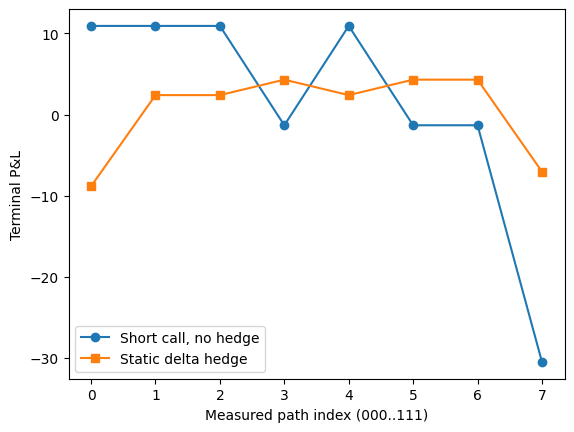

Unhedged / hedged P&L std: 14.246288262071923 5.105514027236635
Price absolute sampling error: 0.5493638180492351
3-step model discretization error vs Black-Scholes: 0.6413148267081059
Finite-shot parity residual: 0.38031709298805083


In [6]:
final = case.analyze(local_results)
plt.plot(final['unhedged_terminal_pnl'], 'o-', label='Short call, no hedge')
plt.plot(final['hedged_terminal_pnl'], 's-', label='Static delta hedge')
plt.xlabel('Measured path index (000..111)'); plt.ylabel('Terminal P&L'); plt.legend(); plt.show()
print('Unhedged / hedged P&L std:', final['unhedged_pnl_std'], final['hedged_pnl_std'])
print('Price absolute sampling error:', abs(final['call_price'] - case.reference['call_price']))
print('3-step model discretization error vs Black-Scholes:',
      case.reference['call_price'] - case.reference['black_scholes_call'])
print('Finite-shot parity residual:', final['put_call_parity_residual'])

## 5.1 统计边界与硬件验收状态

        优化案例另外区分可行率、可行条件下最优命中率、无条件最优命中率及条件平均目标值。
        风险案例使用保留离散分位点规则的多项分布 bootstrap，并用 DKW 范围检查 VaR 是否稳定。
        未观测尾部在经验 bootstrap 中仍然没有概率质量，因此这些区间不能认证未见的稀有风险。
        各状态概率给出 Bonferroni 调整的 Wilson 近似区间；TVD 仅作分布诊断。
        没有事先批准的业务容差，不能自行宣称硬件 PASS。本地结果的硬件状态始终为 NOT_EXECUTED。

In [7]:
from quantumbridge.finance.acceptance import analyze_case_evidence
sampling_acceptance = analyze_case_evidence(case, local_results)
print('Hardware acceptance:', sampling_acceptance['hardware_status'])
for name, diagnostic in sampling_acceptance['experiment_diagnostics'].items():
    print(name, '| ideal-vs-local TVD:', diagnostic['total_variation_distance'])
    if 'optimization' in diagnostic:
        pretty({key: value for key, value in diagnostic['optimization'].items() if key != 'feasible_states'})
    if 'risk_uncertainty' in diagnostic:
        pretty(diagnostic['risk_uncertainty'])

Hardware acceptance: NOT_EXECUTED
risk_neutral_paths | ideal-vs-local TVD: 0.03143191221041372


## 6. 同一电路接入夸父真机

        本批已获 owner 授权的上限：总计20个任务（包括位序校准），每任务1024 shots，最多6量子比特，
        遇收费提示停止。实际五类共8个业务电路，加1个非对称位序校准，共9个任务、9216 shots。
        通过 `QB_FINANCE_RUN_CLOUD=1` 显式开启；有效密钥仅通过 `QUAFU_TOKEN` 或
        `QUAFU_API_TOKEN` 进入内核环境，**不要写在代码格中**。
        Python>=3.12 的云环境需要项目已有的 `quafu-cloud` 可选依赖。

        `QB_QUAFU_BACKEND` 可指定真实设备，默认 Dongling（不保证当前在线）；
        所有五份笔记共享 `output/finance-hardware/session.json` 任务账本。
        每个 task ID 在等待结果前落盘，超时后重跑只取回该任务，不自动重复提交。
        该账本不能被多个内核同时写入。一次完整批次应顺序执行这五份笔记。
        不删除账本来重试；服务端接受与本地落盘之间仍有崩溃窗口，应先核对任务页。

        校准制备 $|10angle$，从 counts 识别 q0-first/q0-last；优势频率不足80%时停止。
        硬件结果必须包含真实任务 ID、实际 shots、原始 counts、位序与电路 SHA256。
        没有最终 counts 时不能标为硬件验收通过，也不会拿本地结果填充。
        SDK没有账单报价接口；限制任务/shot 数不等于保证免费。

Previously retrieved real hardware counts; no new submission:
{
  "case": "derivatives",
  "hardware_status": "INCONCLUSIVE",
  "hardware_status_reason": "business tolerances not approved; receipt consistency is not independent hardware certification",
  "reference": {
    "call_price": 10.054718210561122,
    "delta": 0.6069969747193295,
    "black_scholes_call": 9.413403383853016,
    "discretization_note": "binomial-vs-Black-Scholes difference is model error, not shot error"
  },
  "ideal_circuit_analysis": {
    "call_price": 10.054718210561122,
    "put_price": 7.0992715654119705,
    "delta": 0.6069969747193295,
    "call_price_standard_error": 0.41151420842775266,
    "call_approximate_95pct_interval": [
      9.248150362042727,
      10.861286059079516
    ],
    "delta_standard_error": 0.018380717954062584,
    "unhedged_terminal_pnl": [
      10.3609299676977,
      10.3609299676977,
      10.3609299676977,
      -1.879160276869058,
      10.3609299676977,
      -1.8791602768

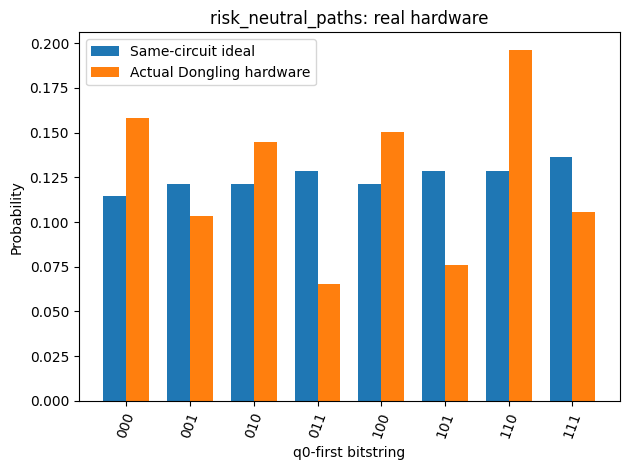

In [8]:
cloud_results = None
if os.environ.get('QB_FINANCE_RUN_CLOUD') == '1':
    session = FinanceCloudSession.from_environment(
        os.environ.get('QB_QUAFU_BACKEND', 'Dongling'),
        journal=ROOT / 'output' / 'finance-hardware' / 'session.json',
        max_tasks=20, shots=1024, max_qubits=6)
    pretty(session.preflight(list(build_finance_cases().values())))
    cloud_results = session.run(case, timeout=300, poll_interval=2)
    assert all(result['hardware_access'] for result in cloud_results.values())
    pretty({name: {k: result[k] for k in ['task_id', 'backend', 'shots', 'raw_counts', 'provider_bit_order']}
            for name, result in cloud_results.items()})
    print('REAL CLOUD FINANCIAL RESULTS:')
    pretty(case.analyze(cloud_results))
elif os.environ.get('QB_FINANCE_REPLAY_HARDWARE') == '1':
    evidence_path = ROOT / 'output' / 'jupyter-notebook' / 'finance' / (case.key + '_hardware_evidence.json')
    existing = json.loads(evidence_path.read_text(encoding='utf-8'))
    cloud_results = existing['hardware_results']
    print('Previously retrieved real hardware counts; no new submission:')
    pretty(analyze_case_evidence(case, cloud_results))
else:
    print('HARDWARE NOT EXECUTED: cloud opt-in disabled. All results above are LOCAL ONLY.')
if cloud_results is not None:
    hardware_acceptance = analyze_case_evidence(case, cloud_results)
    print('Hardware execution COMPLETE; numerical acceptance:', hardware_acceptance['hardware_status'])
    for name, result in cloud_results.items():
        print('Actual task:', result['task_id'], '| backend:', result['backend'], '| shots:', result['shots'])
        print('Raw provider counts:', result['raw_counts'])
        print('Normalized q0-first counts:', result['counts'])
        xs = np.arange(len(result['probabilities']))
        ideal = local_results[name]['ideal_probabilities']
        plt.bar(xs - .18, ideal, width=.36, label='Same-circuit ideal')
        plt.bar(xs + .18, result['probabilities'], width=.36, label='Actual ' + result['backend'] + ' hardware')
        plt.xticks(xs, labels(case.experiments[name].num_qubits), rotation=70)
        plt.xlabel('q0-first bitstring'); plt.ylabel('Probability'); plt.title(name + ': real hardware')
        plt.legend(); plt.tight_layout(); plt.show()

## 7. 本案例的交付证据

        下格保存可复查的输入、参考、中间结果、模拟 counts 和分析结果。
        `hardware_status=not_executed` 不是通过认证；只在取得真实 counts 时写入硬件证据。
        云平台执行硬件电路，本地执行数据加载、优化和金融后处理。

In [9]:
evidence = {
    'case': case.key, 'title': case.title, 'inputs': case.inputs,
    'intermediate': case.intermediate, 'reference': case.reference,
    'local_results': local_results, 'local_analysis': case.analyze(local_results),
    'hardware_status': 'completed' if cloud_results is not None else 'not_executed',
    'hardware_results': cloud_results,
    'hardware_analysis': None if cloud_results is None else case.analyze(cloud_results),
    'acceptance': analyze_case_evidence(case, cloud_results),
    'scope': 'synthetic small research case; not full industry coverage or investment advice',
}
suffix = '_hardware_evidence.json' if cloud_results is not None else '_evidence.json'
destination = ROOT / 'output' / 'jupyter-notebook' / 'finance' / (case.key + suffix)
destination.parent.mkdir(parents=True, exist_ok=True)
destination.write_text(json.dumps(evidence, ensure_ascii=False, indent=2, allow_nan=False), encoding='utf-8')
print('Evidence:', destination.name, '| hardware:', evidence['hardware_status'])

Evidence: derivatives_hardware_evidence.json | hardware: completed


## 8. 练习、边界和扩展

        练习：将本地采样从1024增加到4096 shots，保持模型和电路不变，比较误差。
        下面只运行模拟器，**不会增加云端shots或创建新任务**。
        解答思路：比较多个随机种子的误差分布，不能要求每个种子的误差都单调下降。
        采样标准误差一般随 $1/\sqrt N$ 缩小；量子硬件偏差不会由增加 shots 自动消失。

        常见陷阱：把纯 Python 预处理称为硬件能力、把本地 counts 称为真机、按最多出现的位串直接作业务决策、
        忽略负相关符号、混淆风险中性和真实概率、把1024 shots尾部结果当作精确VaR。
        后续可扩展更大模型、真实数据、读出误差缓解、硬件闭环与独立回测；这里没有宣称这些已实现。

In [10]:
more_shots = run_local(case, shots=4096, seed=20261023)
print('LOCAL 4096-shot comparison (no cloud):')
pretty(case.analyze(more_shots))

LOCAL 4096-shot comparison (no cloud):
{
  "call_price": 9.704452944457348,
  "put_price": 7.410818096449405,
  "delta": 0.5851103983678927,
  "call_price_standard_error": 0.20432895904921683,
  "call_approximate_95pct_interval": [
    9.303968184720881,
    10.104937704193812
  ],
  "delta_standard_error": 0.00919407388337623,
  "unhedged_terminal_pnl": [
    9.99999753615463,
    9.99999753615463,
    9.99999753615463,
    -2.240092708412128,
    9.99999753615463,
    -2.240092708412128,
    -2.240092708412128,
    -31.398248271897025
  ],
  "hedged_terminal_pnl": [
    -8.912653525850395,
    1.8372814211254251,
    1.8372814211254251,
    3.13978492128021,
    1.8372814211254251,
    3.13978492128021,
    3.13978492128021,
    -8.95763062478106
  ],
  "unhedged_pnl_std": 13.47366390971203,
  "hedged_pnl_std": 4.992860377394711,
  "put_call_parity_residual": -0.6618117971412403,
  "model": "3-step risk-neutral binomial; static delta hedge; not a continuous dynamic hedge"
}


## 9. 数学与接口参考

        本项目独立实现，未拷贝上游 SDK 源码或教程代码。
        [Qiskit Finance：组合优化](https://qiskit-community.github.io/qiskit-finance/tutorials/01_portfolio_optimization.html)、
        [欧式看涨期权](https://qiskit-community.github.io/qiskit-finance/tutorials/03_european_call_option_pricing.html)、
        [信用风险](https://qiskit-community.github.io/qiskit-finance/tutorials/09_credit_risk_analysis.html)
        提供应用定义参考；本批采用直接采样，而不是复现其 QAE 算法。
        [Quantum Risk Analysis](https://arxiv.org/abs/1806.06893)、
        [Option Pricing using Quantum Computers](https://arxiv.org/abs/1905.02666) 是算法背景，
        论文中的加速结论不适用于本批直接采样实现。
        [QuarkStudio 电路提交接口](https://quarkstudio.readthedocs.io/en/latest/usage/code/transpiler/)
        用于 `quark.Task`、QASM 和 `repeat × 1024` 传输合同。